# Sprint 3 · Semana 7: búsqueda de hiperparámetros, aleatoria y bayesiana

Tesis: Detección Automatizada y Priorización de Eventos Adversos en Notas Clínicas mediante un Flujo de Procesamiento (Pipeline) de NLP y
Aprendizaje Automático — Aplicación de la Matriz de Priorización del Modelo GEMSES sobre MIMIC-IV

Autor: Carlos Pérez Pérez · Curso: MIA-14 Trabajo de Investigación II · Docente: Dr. Glen Rodríguez · 28 de octubre de 2026

El presente cuaderno reúne el experimento de la semana 7, el cual abre el Sprint 3 con la búsqueda de hiperparámetros del modelo vigente, es
decir, la configuración A+B+C entrenada con la variante D2 de los datos. El cuaderno no vuelve a entrenar el modelo, dado que la corrida completa
requirió cerca de 1.8 horas de cómputo, sino que lee los resultados que deja el script `src/experimentos_hp.py` en la carpeta
`reportes/` y a partir de ellos construye cada tabla y cada figura. De esta manera, cada cifra del texto puede verificarse en las
celdas de código, y no se requiere acceso a los datos de MIMIC-IV, protegidos por el acuerdo de uso de PhysioNet.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import figuras_hp  # mismas funciones que dibujan reportes/figuras/fig_hp_*.png

leer = lambda n: json.loads((RAIZ / "reportes" / n).read_text(encoding="utf-8"))
R, D = leer("hp_resultados.json"), leer("datos_resultados.json")
ens = pd.read_csv(RAIZ / "reportes" / "hp_ensayos.csv", keep_default_na=False)
plt.rcParams.update({"font.size": 9})
print("Resultados leídos:", R["generado"], "· semilla", R["semilla"], "· Optuna", R["optuna"], "· decisión:", R["decision"])

Resultados leídos: 2026-10-28T10:17:34 · semilla 42 · Optuna 5.0.0 · decisión: se mantiene la configuración actual


## 1. Punto de partida: el modelo vigente

Al cierre del Sprint 2 se adoptó la variante D2 con la configuración A+B+C. Su PR-AUC (área bajo la curva de precisión y sensibilidad) fue
0.8534 ± 0.0041 en la validación cruzada de 5 *folds* y 0.8671 en *test*, en ambos casos sobre las epicrisis
sin etiqueta dudosa. Ese modelo conservó los hiperparámetros (valores que se fijan antes de entrenar y que el modelo no aprende de los datos)
del *baseline* de la semana 3. Esos valores son C igual a 1, clases balanceadas y 20 000 palabras con
min_df de 3, y la semana 5 los repitió para los bigramas. Por ello, el cierre del Sprint 2 recomendó ajustar C con pocos
valores, y en esta semana esa recomendación se amplía a una búsqueda que incluye también el tamaño del vocabulario, el peso de las clases y la
forma de contar las palabras.

In [2]:
cv6, te6 = D["cv"]["D2"]["comun"]["pr_auc"], D["test"]["D2"]["comun"]
print("D2 con A+B+C · validación cruzada (5 folds):", cv6["media"], "±", cv6["std"], "· test:", te6["pr_auc"], te6["pr_auc_ic95_pacientes"])

D2 con A+B+C · validación cruzada (5 folds): 0.8534 ± 0.0041 · test: 0.8671 [0.8589, 0.8749]


Fuente: elaboración propia a partir de `reportes/datos_resultados.json`.

## 2. Búsqueda aleatoria frente a búsqueda bayesiana

Bergstra y Bengio (2012) señalan que, con el mismo presupuesto, los ensayos elegidos al azar son más eficientes que los de una grilla. Según
los mismos autores, en cada conjunto de datos solo unos pocos hiperparámetros influyen de verdad en el resultado, y esos pocos no son los
mismos de un conjunto a otro. Por ello, proponen la búsqueda aleatoria como punto de comparación de los métodos que eligen cada ensayo a partir
de los resultados de los anteriores, grupo al cual pertenece la búsqueda bayesiana.

La búsqueda bayesiana de este experimento usa Optuna (Akiba et al., 2019), en concreto el estimador TPE (*Tree-structured Parzen Estimator*)
multivariado, que es la opción por defecto de Optuna 5.0.0 cuando hay un solo objetivo. La documentación de Optuna remite, entre otros, a
Bergstra et al. (2011) y, para la variante multivariada, a Falkner et al. (2018). El TPE separa los ensayos ya hechos en los de mejor resultado
y el resto. En su variante multivariada, estima con cada grupo una distribución conjunta de todos los hiperparámetros y propone la
configuración en la que la primera distribución es más alta en relación con la segunda.

En consecuencia, la comparación responde a una pregunta práctica, es decir, si aprender de los ensayos anteriores encuentra una configuración
mejor que el azar cuando ambos métodos disponen del mismo número de ensayos.

## 3. Diseño del experimento, fijado antes de ver los resultados

El diseño, el presupuesto y la regla de decisión se escribieron en `config/config.yaml` (sección `hiperparametros`) antes de ejecutar la
búsqueda. Dado que ese archivo no tiene un *commit* anterior a la corrida, la única prueba de ese prerregistro es el registro
`logs/experimentos_hp_20261028_081924.log`, escrito al construir la caché de conteos y antes del primer ensayo. Ese registro recoge el espacio
de búsqueda, la regla de decisión y el presupuesto inicial de 18 ensayos por método.

Se mantuvo el modelo A+B+C sin cambios de diseño, es decir, las palabras de la epicrisis (A), los pares de palabras consecutivas (B) y las
variables de la hospitalización con el largo de la nota (C), seguidos de una regresión logística. Se entrenó con las filas de la variante D2,
igual que en `src/experimentos_datos.py`, y cada configuración se evaluó en las epicrisis de validación sin etiqueta dudosa, que son las mismas
con las cuales se eligió D2 en la semana 6.

La búsqueda se hizo solo en la partición de entrenamiento, con validación cruzada `StratifiedGroupKFold` de 3 *folds*
(partes en que se divide el conjunto de entrenamiento para entrenar con las demás y evaluar con la que queda) y semilla 42. La división se hizo
por paciente, de modo que un paciente nunca está en dos partes, y se usaron 3 *folds* y no 5 para reducir el tiempo de
cada ensayo. La mejor configuración se confirmó después frente a la actual con los 5 *folds* del proyecto, los mismos
de las semanas 5 y 6, y la partición de *test* se usó una sola vez, al final, para esas dos configuraciones.

La métrica es la PR-AUC media de los *folds*, como en las semanas anteriores, y además se registraron la ROC-AUC y el tiempo de cada ensayo.
El Cuadro 1 presenta los hiperparámetros que se buscaron, los valores probados y los de la configuración actual.

Cuadro 1. Espacio de búsqueda

| Hiperparámetro | Qué controla | Valores probados | Configuración actual |
|---|---|---|---|
| C | inverso de la fuerza de la regularización de la regresión logística (a mayor C, menos se penalizan los coeficientes) | continuo, log-uniforme entre 0.001 y 100 | 1 |
| `max_features` de A | número máximo de palabras del vocabulario | 10 000, 20 000, 40 000 y 60 000 | 20 000 |
| `min_df` de A | número mínimo de epicrisis en las que debe aparecer una palabra | 2, 3 y 5 | 3 |
| `max_features` de B | número máximo de bigramas del vocabulario | 10 000, 20 000 y 40 000 | 20 000 |
| `min_df` de B | número mínimo de epicrisis en las que debe aparecer un bigrama | 2, 3 y 5 | 3 |
| `class_weight` | peso de las clases en el entrenamiento | *balanced* (compensa la proporción de cada clase) o sin pesos | *balanced* |
| `sublinear_tf` | cuenta las repeticiones de un término como 1 + log(frecuencia) y no como la frecuencia | activado o desactivado, con el mismo valor en A y en B | activado |

Fuente: elaboración propia a partir de `config/config.yaml`. El valor de 60 000 palabras corresponde al modelo de la tesis registrado en la
sección `baseline` del mismo archivo, y `sublinear_tf` se cambia sobre el pipeline de `src/features.py` sin modificar sus bloques.

Se compararon dos métodos con el mismo presupuesto de 15 ensayos cada uno, ambos con Optuna 5.0.0 y semilla 42, es decir, la
búsqueda aleatoria (`RandomSampler`) y la bayesiana (`TPESampler` multivariado). La bayesiana empieza con 5 ensayos al azar y, como usa la
misma semilla, esos ensayos coinciden con los 5 primeros de la aleatoria, por lo cual se evaluaron una sola vez y se reutilizaron. De esta
manera, ambos métodos parten del mismo punto, y la diferencia entre ellos se debe solo a la forma de elegir los ensayos siguientes.

El presupuesto se fijó primero en 18 ensayos por método y se redujo a 15 antes de iniciar la búsqueda, por una estimación previa de que los
ensayos con C alto tardarían varios minutos cada uno. Esa estimación no quedó registrada, y los dos valores del presupuesto constan en los
registros de las corridas en `logs/`. Asimismo, la corrida no fijó el parámetro `multivariate` del `TPESampler`, de modo que se aplicó el
valor por defecto de Optuna 5.0.0, que con un solo objetivo equivale a `multivariate=True`. Después de la corrida, ese valor se hizo explícito
en el script y en `config/config.yaml`, y la celda siguiente verifica que la secuencia de ensayos que propone es idéntica a la registrada.

La regla de decisión, también fijada antes de correr, establece que la configuración ajustada reemplaza a la actual solo si mejora la PR-AUC de
la validación cruzada de 5 *folds* en al menos 4 de ellos. Además, la mejora media debe superar
una desviación estándar de las diferencias por *fold*, y si no se cumplen
las dos condiciones se mantiene la configuración actual. Para no repetir la comparación con varias configuraciones, la candidata es una sola,
la de mayor PR-AUC media entre los ensayos de los dos métodos.

Es preciso tomar en consideración que el lote de la revisión ciega de las hipótesis específicas HE2 y HE3 ya se generó con la configuración
actual (D2, A+B+C, corte de probabilidad 0.5), y que esa revisión está en curso. Por consiguiente, si la regla adoptara otra configuración, el
lote no se regenera, y se declara que HE2 y HE3 se refieren a la configuración con la cual se muestreó.

In [3]:
H = R["parametros"]
print("Configuración actual:", R["configuracion_actual"])
print("Presupuesto:", H["n_ensayos"], "ensayos por método · ensayos iniciales al azar de la bayesiana:", H["ensayos_iniciales_tpe"],
      "· folds de búsqueda:", H["n_folds_busqueda"], "· folds de confirmación:", H["n_folds_confirmacion"])
print("Regla:", H["regla"])
print("Protocolo:", R["protocolo"])
for f in sorted((RAIZ / "logs").glob("experimentos_hp_2*.log")):     # corrida de la caché y corrida principal
    lineas = f.read_text(encoding="utf-8").splitlines()
    print(f.name, "·", lineas[0][:19], "·", next(l for l in lineas if "presupuesto:" in l).split(" | ")[-1])
    print("   ", next(l for l in lineas if "REGLA PRERREGISTRADA" in l).split(" | ")[-1][:110], "…")

Configuración actual: {'C': 1.0, 'A_max_features': 20000, 'A_min_df': 3, 'B_max_features': 20000, 'B_min_df': 3, 'class_weight': 'balanced', 'sublinear_tf': True}
Presupuesto: 15 ensayos por método · ensayos iniciales al azar de la bayesiana: 5 · folds de búsqueda: 3 · folds de confirmación: 5
Regla: {'folds_mejores_minimo': 4, 'desviaciones_minimas': 1.0}
Protocolo: búsqueda: StratifiedGroupKFold(3, shuffle=True, random_state=42) por subject_id en train; confirmación: StratifiedGroupKFold(5, shuffle=True, random_state=42) (los folds de las semanas 5 y 6); entrenan las filas de D2; métrica: PR-AUC media en las epicrisis de validación sin etiqueta dudosa; test usado una vez
experimentos_hp_20261028_081924.log · 2026-10-28 08:19:24 · presupuesto: 18 ensayos por método · bayesiana con 5 ensayos iniciales al azar
    REGLA PRERREGISTRADA: la candidata reemplaza a la actual solo si mejora la PR-AUC (5 folds) en al menos 4 de 5 …
experimentos_hp_20261028_084713.log · 2026-10-28 08:47:13 · pr

In [4]:
# Verificación del TPE multivariado: se vuelve a pedir a Optuna la secuencia de ensayos, respondiendo con la PR-AUC
# registrada en hp_ensayos.csv (sin entrenar), y se compara con los parámetros que propuso la corrida real.
import numpy as np
import optuna
import experimentos_hp as hp          # espacio de búsqueda del script
%matplotlib inline

optuna.logging.set_verbosity(optuna.logging.WARNING)
cols = list(R["configuracion_actual"])
reg = pd.read_csv(RAIZ / "reportes" / "hp_ensayos.csv", keep_default_na=False, float_precision="round_trip")
igual = lambda p, r: all(np.isclose(p[c], r[c], rtol=1e-12) if c == "C" else p[c] == r[c] for c in cols)

def repetir(sampler):
    sugeridos = []
    def objetivo(trial):
        p = hp.espacio(trial, H["espacio"])
        sugeridos.append(p)
        r = next((r for r in reg.to_dict("records") if igual(p, r)), None)
        if r is None:
            raise optuna.TrialPruned()      # la secuencia ya se separó de la registrada
        return r["pr_auc_media"]
    optuna.create_study(direction="maximize", sampler=sampler).optimize(objetivo, n_trials=H["n_ensayos"])
    return sugeridos

S, k0 = R["semilla"], H["ensayos_iniciales_tpe"]
for nombre, metodo, sampler in (
        ("RandomSampler(seed=42)", "aleatoria", optuna.samplers.RandomSampler(seed=S)),
        ("TPESampler(seed=42, multivariate=True)", "bayesiana", optuna.samplers.TPESampler(seed=S, n_startup_trials=k0, multivariate=True)),
        ("TPESampler(seed=42, multivariate=False), control", "bayesiana",
         optuna.samplers.TPESampler(seed=S, n_startup_trials=k0, multivariate=False))):
    r_m = reg[reg.metodo == metodo].sort_values("ensayo").to_dict("records")
    print(f"{nombre}: {sum(igual(p, r) for p, r in zip(repetir(sampler), r_m))} de {len(r_m)} ensayos iguales a los registrados")

RandomSampler(seed=42): 15 de 15 ensayos iguales a los registrados
TPESampler(seed=42, multivariate=True): 15 de 15 ensayos iguales a los registrados
TPESampler(seed=42, multivariate=False), control: 5 de 15 ensayos iguales a los registrados


Como se aprecia en la salida anterior, con `multivariate=True` explícito Optuna propone los mismos 15 ensayos bayesianos que registró la
corrida, mientras que con el TPE independiente (`multivariate=False`) la secuencia solo coincide en los 5 ensayos iniciales al azar. De esta
manera, se confirma que la corrida usó el TPE multivariado.

Para que cada ensayo tarde minutos y no horas, en cada partición las palabras y los bigramas se contaron una sola vez y los conteos se
guardaron en una caché. Así, cada ensayo solo elige el vocabulario con la misma regla de scikit-learn y aplica la ponderación TF-IDF, con
matrices idénticas a las del *pipeline* de `src/features.py`. El script incluye un control de esa equivalencia contra el propio *pipeline*, que
se ejecuta con la opción `--prueba` sobre una muestra de 4 000 epicrisis de *train*, y su registro se conserva en `logs/`. Adicionalmente, la
sección 4 verifica que la configuración actual reproduce los resultados de la semana 6.

In [5]:
prueba = sorted((RAIZ / "logs").glob("experimentos_hp_prueba_*.log"))[-1]
lineas = prueba.read_text(encoding="utf-8").splitlines()
print(prueba.name, "·", next(l for l in lineas if "pacientes compartidos" in l).split(" | ")[-1])
print(next(l for l in lineas if "control de equivalencia" in l).split(" | ")[-1])

experimentos_hp_prueba_20261028_104516.log · train 4,000 (entrenan 3,527 filas de D2; evaluación común 3,527) · test 1,500 (evaluación común 1,302) · 0 pacientes compartidos
control de equivalencia con el pipeline de features.py (C=3.7 · A 10000/5 · B 10000/2 · class_weight=ninguno · sublinear_tf=False): diferencia máxima de probabilidad 0.00e+00


## 4. Control de reproducción

Como se aprecia en la Tabla 1, la configuración actual medida en esta corrida reproduce la PR-AUC por *fold* de D2 que registró la semana 6,
sin diferencias hasta el sexto decimal (diferencia máxima de 0.000000). De igual forma, en *test* se obtuvo 0.8671
en las epicrisis sin etiqueta dudosa, frente a 0.8671 de la semana 6, y 0.8580 con
todas las epicrisis, frente a 0.8580. De esta manera, se confirma que la búsqueda parte del mismo modelo y de los
mismos datos que la semana anterior.

In [6]:
c, t = R["control_reproduccion_cv"], R["control_reproduccion_test"]
t1 = pd.DataFrame({"semana 6 (D2)": c["pr_auc_semana6"], "esta corrida (actual)": c["pr_auc_esta_corrida"]},
                  index=pd.Index(range(1, len(c["pr_auc_semana6"]) + 1), name="Tabla 1. PR-AUC por fold (5 folds)"))
display(t1)
print("Diferencia máxima:", c["dif_maxima"], "· reproduce:", c["reproduce"])
print("Test sin etiqueta dudosa:", t["pr_auc_comun_semana6"], "→", t["pr_auc_comun_esta_corrida"],
      "· todas las epicrisis:", t["pr_auc_completa_semana6"], "→", t["pr_auc_completa_esta_corrida"], "· reproduce:", t["reproduce"])

,semana 6 (D2),esta corrida (actual)
Tabla 1. PR-AUC por fold (5 folds),,
1,0.856697,0.856697
2,0.852738,0.852738
3,0.846717,0.846717
4,0.854189,0.854189
5,0.856627,0.856627


Diferencia máxima: 0.0 · reproduce: True
Test sin etiqueta dudosa: 0.8671 → 0.8671 · todas las epicrisis: 0.858 → 0.858 · reproduce: True


Fuente: elaboración propia a partir de `reportes/hp_resultados.json` y `reportes/datos_folds.csv`.

## 5. Resultados de la búsqueda

La Tabla 2 presenta los cinco mejores ensayos de cada método, ordenados por la PR-AUC media de 3 *folds*, con sus
hiperparámetros, la desviación estándar entre *folds*, la ROC-AUC y el tiempo de cómputo de cada ensayo. En total se registraron 30
ensayos, 15 por método, que corresponden a 25 configuraciones distintas, dado que los 5 primeros ensayos de la bayesiana se
reutilizaron de la aleatoria.

In [7]:
cols = ["C", "A_max_features", "A_min_df", "B_max_features", "B_min_df", "class_weight", "sublinear_tf", "pr_auc_media", "pr_auc_std",
        "roc_auc_media", "segundos", "reutilizado_de"]
t2 = (ens.sort_values("pr_auc_media", ascending=False).groupby("metodo", sort=False).head(5)
         .sort_values(["metodo", "pr_auc_media"], ascending=[True, False]).set_index(["metodo", "ensayo"])[cols])
t2.index.names = ["Tabla 2. Método", "ensayo"]
display(t2.style.format({"C": "{:.4g}", "pr_auc_media": "{:.4f}", "pr_auc_std": "{:.4f}", "roc_auc_media": "{:.4f}", "segundos": "{:.0f}"}))
ref = R["referencia_actual_busqueda"]
print("Configuración actual en los mismos 3 folds: PR-AUC", round(ref["pr_auc_media"], 4), "±", round(ref["pr_auc_std"], 4),
      "· ROC-AUC", round(ref["roc_auc_media"], 4))
for m, r in R["mejor_por_metodo"].items():
    print(f"Mejor {m}: ensayo {r['ensayo']} · PR-AUC {r['pr_auc_media']:.4f} ± {r['pr_auc_std']:.4f} · diferencia con la actual "
          f"{r['pr_auc_media'] - ref['pr_auc_media']:+.4f}")
print("Candidata:", R["candidata"])
print("Ensayos registrados:", len(ens), "· configuraciones distintas evaluadas:", int((ens.reutilizado_de == "").sum()),
      "· mejor bayesiana menos mejor aleatoria:", round(R["mejor_por_metodo"]["bayesiana"]["pr_auc_media"] - R["mejor_por_metodo"]["aleatoria"]["pr_auc_media"], 4))

Configuración actual en los mismos 3 folds: PR-AUC 0.8498 ± 0.0009 · ROC-AUC 0.8546
Mejor aleatoria: ensayo 4 · PR-AUC 0.8471 ± 0.0014 · diferencia con la actual -0.0027
Mejor bayesiana: ensayo 14 · PR-AUC 0.8480 ± 0.0024 · diferencia con la actual -0.0018
Candidata: {'metodo': 'bayesiana', 'parametros': {'C': 2.318133815156313, 'A_max_features': 10000, 'A_min_df': 3, 'B_max_features': 10000, 'B_min_df': 2, 'class_weight': 'ninguno', 'sublinear_tf': False}}
Ensayos registrados: 30 · configuraciones distintas evaluadas: 25 · mejor bayesiana menos mejor aleatoria: 0.0009


Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv` y `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 2, el mejor ensayo de la búsqueda aleatoria fue el n.º 4, el cual alcanzó una PR-AUC de
0.8471 ± 0.0014. Sus hiperparámetros fueron C de 0.976, 10 000 palabras con min_df de 3, 10 000 bigramas con min_df de 5, class_weight sin pesos y sublinear_tf activado. Por su parte, el mejor de la
bayesiana fue el n.º 14, el cual alcanzó 0.8480 ± 0.0024 con C de 2.32, 10 000 palabras con min_df de 3, 10 000 bigramas con min_df de 2, class_weight sin pesos y sublinear_tf desactivado. Este
último pasó a ser la candidata, por tener la mayor PR-AUC media de los dos métodos. Sin embargo, la configuración actual obtuvo 0.8498 ± 0.0009 en los mismos 3 *folds*,
de modo que ningún ensayo de los dos métodos la superó, y la candidata quedó
0.0018 por debajo de ella.

Figura 1. Mejor resultado acumulado y resultado de cada ensayo, por método

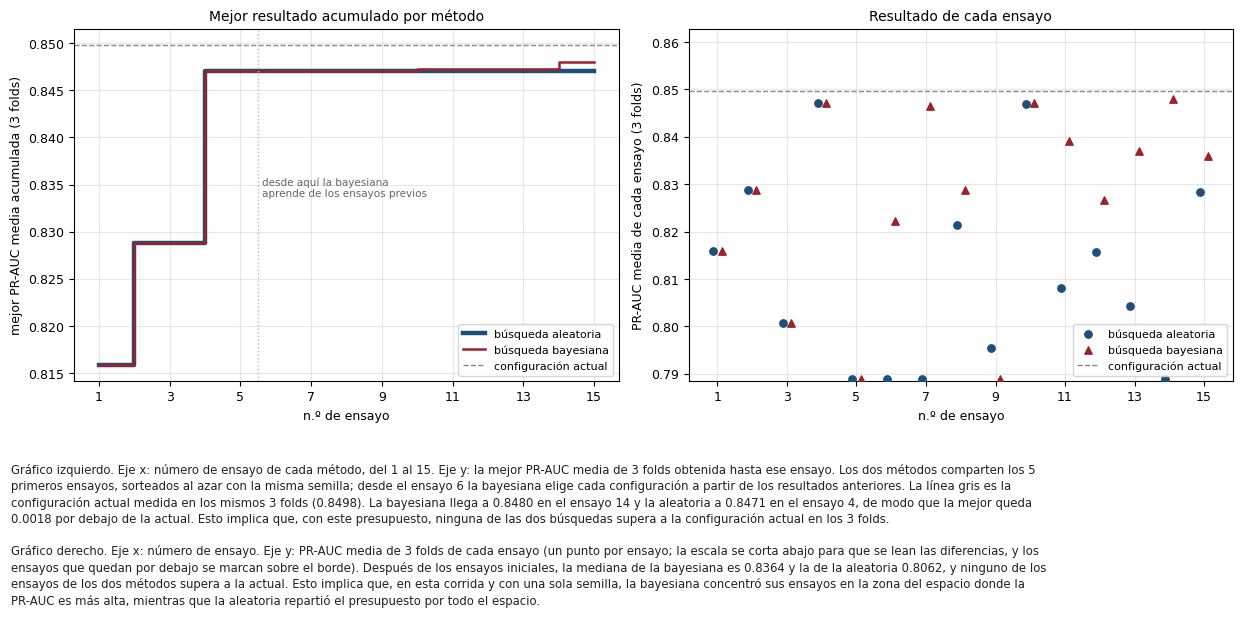

In [8]:
fig = figuras_hp.fig_busqueda(R, ens)
plt.show()

Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv`.


En la Figura 1 se observa que las dos búsquedas recorren el mismo camino durante los 5 ensayos iniciales, en los cuales el mejor resultado
acumulado llega a 0.8471. A partir del ensayo 6, la aleatoria no vuelve a mejorar, mientras que la bayesiana mejora en los ensayos 10 y 14 (hasta 0.8480), y ninguna de
las dos alcanza la línea de la configuración actual. Asimismo, en el gráfico derecho se aprecia que, después de los ensayos iniciales, la
mediana de la bayesiana (0.8364) supera a la de la aleatoria (0.8062). Esta diferencia es
coherente con que el TPE propuso C de al menos 0.1 en 9 de sus 10 ensayos propios, frente a 4 de
10 de la aleatoria en los mismos ensayos, y evitó así la zona de C pequeño donde la PR-AUC cae. En consecuencia,
en esta corrida y con una sola semilla, la búsqueda bayesiana aprovechó mejor el presupuesto, en el sentido de que evaluó menos configuraciones
con PR-AUC baja. Aun así, con 15 ensayos su mejor resultado superó al de la aleatoria en solo 0.0009.

In [9]:
k0 = R["parametros"]["ensayos_iniciales_tpe"]
for m, g in ens.groupby("metodo", sort=False):
    v = g.sort_values("ensayo")
    print(f"{m}: mejor acumulado por ensayo", [round(x, 4) for x in v.pr_auc_media.cummax()],
          f"· mediana después del ensayo {k0}: {v[v.ensayo > k0].pr_auc_media.median():.4f}",
          f"· ensayos sobre la actual: {(v.pr_auc_media > R['referencia_actual_busqueda']['pr_auc_media']).sum()}",
          f"· ensayos propios (después del {k0}) con C de al menos 0.1: {(v[v.ensayo > k0].C >= 0.1).sum()} de {(v.ensayo > k0).sum()}")

aleatoria: mejor acumulado por ensayo [0.8158, 0.8288, 0.8288, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471] · mediana después del ensayo 5: 0.8062 · ensayos sobre la actual: 0 · ensayos propios (después del 5) con C de al menos 0.1: 4 de 10
bayesiana: mejor acumulado por ensayo [0.8158, 0.8288, 0.8288, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8471, 0.8472, 0.8472, 0.8472, 0.8472, 0.848, 0.848] · mediana después del ensayo 5: 0.8364 · ensayos sobre la actual: 0 · ensayos propios (después del 5) con C de al menos 0.1: 9 de 10


La Figura 2 muestra cómo cambia la PR-AUC de la búsqueda con cada hiperparámetro, con un punto por cada una de las 25 configuraciones
evaluadas. El panel a) presenta el efecto de C y los paneles b) a g), el de los demás hiperparámetros.

Figura 2. Efecto de cada hiperparámetro en la PR-AUC de la búsqueda

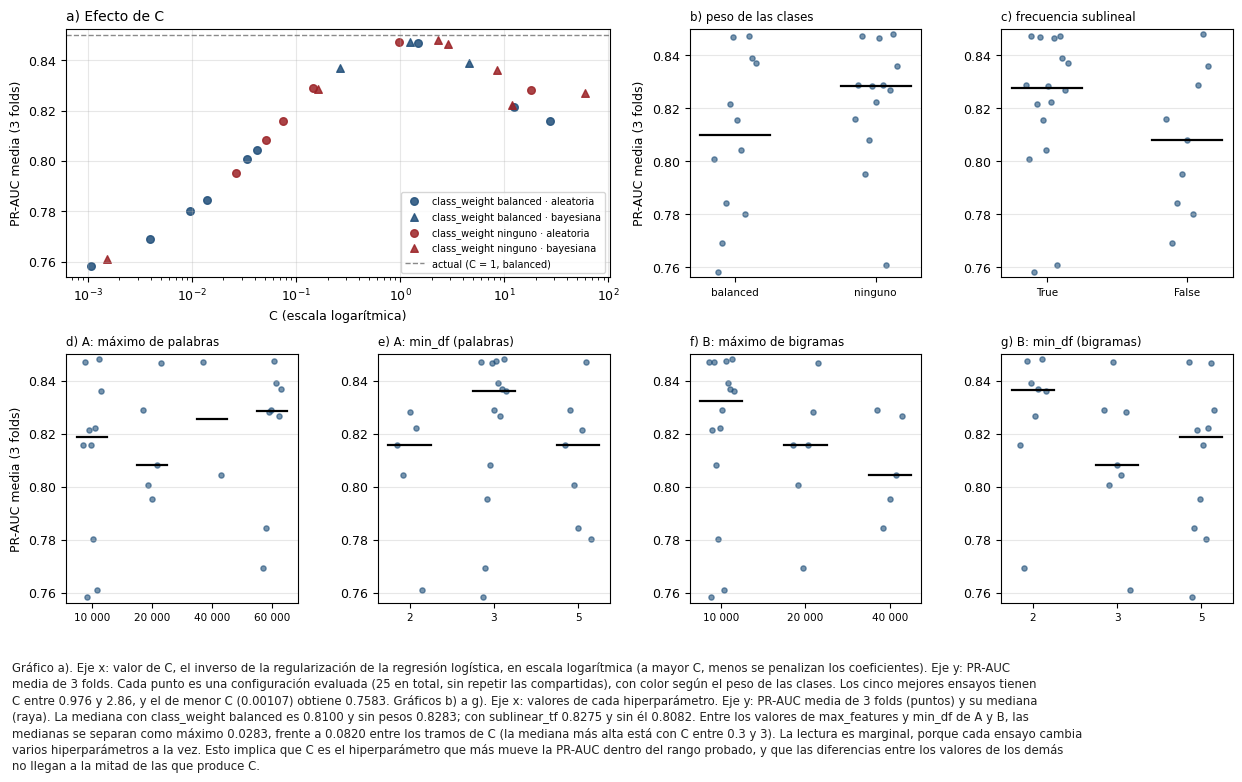

In [10]:
fig = figuras_hp.fig_parametros(R, ens)
plt.show()

Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv`.


En el panel a) de la Figura 2 se observa que la PR-AUC sube con C hasta un máximo en torno a C = 1 y luego desciende. A criterio del autor,
este comportamiento refleja el paso de una regularización excesiva, que impide al modelo aprovechar el texto, a una regularización escasa, que
lo ajusta en exceso a las epicrisis de entrenamiento. Por el contrario, en los paneles b) a g) las medianas de los demás hiperparámetros se
separan bastante menos, y esas diferencias reflejan en parte los valores de C con los cuales coincidieron en cada ensayo, por lo cual se leen
solo como orientación. La Tabla 3 resume el efecto de C por tramos.

In [11]:
u = ens[ens.reutilizado_de == ""]
tramos = pd.cut(u.C, figuras_hp.TRAMOS_C, labels=["hasta 0.01", "0.01 a 0.1", "0.1 a 0.3", "0.3 a 3", "más de 3"])
t3 = u.groupby(tramos, observed=True).pr_auc_media.agg(["count", "median", "max"]).round(4)
t3.columns = ["configuraciones", "PR-AUC mediana", "PR-AUC máxima"]
t3.index.name = "Tabla 3. Tramo de C"
display(t3)
print("Mediana por class_weight:", u.groupby("class_weight").pr_auc_media.median().round(4).to_dict(),
      "· por sublinear_tf:", u.groupby("sublinear_tf").pr_auc_media.median().round(4).to_dict())

,configuraciones,PR-AUC mediana,PR-AUC máxima
Tabla 3. Tramo de C,,,
hasta 0.01,4,0.7651,0.7802
0.01 a 0.1,6,0.8025,0.8158
0.1 a 0.3,3,0.8288,0.8369
0.3 a 3,5,0.8471,0.8480
más de 3,7,0.8268,0.8390


Mediana por class_weight: {'balanced': 0.81, 'ninguno': 0.8283} · por sublinear_tf: {False: 0.8082, True: 0.8275}


Fuente: elaboración propia a partir de `reportes/hp_ensayos.csv`.


Como se aprecia en la Tabla 3, la mediana de la PR-AUC pasa de 0.7651 con C hasta 0.01 a 0.8471 con C entre
0.3 y 3, y vuelve a bajar a 0.8268 con C mayor que 3. De igual forma, la
mediana es de 0.8100 con class_weight balanced y de 0.8283 sin pesos, y de 0.8275 con sublinear_tf activado y
de 0.8082 sin él, diferencias menores que las que produce C. De esta manera, la configuración actual, con C de 1, ya se
encuentra en el tramo de C con la PR-AUC más alta, lo cual es coherente con que la búsqueda no la haya superado.

## 6. Confirmación con los 5 *folds* del proyecto y aplicación de la regla

Siguiendo el diseño, la candidata, es decir, el ensayo 14 de la búsqueda bayesiana, se comparó con la configuración actual en los
5 *folds* del proyecto, sobre las mismas epicrisis de validación sin etiqueta dudosa. La Tabla 4 presenta la PR-AUC de ambas
configuraciones en cada *fold* y la diferencia entre ellas, con su media y su desviación estándar.

In [12]:
c = R["confirmacion_5_folds"]
pa = [f["pr_auc_comun"] for f in c["actual"]["folds"]]
pc = [f["pr_auc_comun"] for f in c["candidata"]["folds"]]
t4 = pd.DataFrame({"actual": pa, "candidata": pc}, index=pd.Index(range(1, len(pa) + 1), name="Tabla 4. PR-AUC por fold (5 folds)"))
t4["candidata − actual"] = t4.candidata - t4.actual
t4.loc["media"] = t4.iloc[:5].mean(); t4.loc["desviación estándar"] = t4.iloc[:5].std()
display(t4.round(4))
g = R["regla"]
print("Folds en que mejora la candidata:", g["folds_mejores"], "de", g["n_folds"], "· criterio de folds (al menos", g["folds_mejores_minimo"], "):", g["criterio_folds"])
print("Diferencia media:", g["dif_media"], "· desviación estándar:", g["dif_std"], "· criterio de desviación:", g["criterio_desviacion"])
print("ROC-AUC media (5 folds): actual", round(c["actual"]["roc_auc_media"], 4), "· candidata", round(c["candidata"]["roc_auc_media"], 4))
print("Diferencias por fold con 6 decimales:", [f"{x:+.6f}" for x in g["diferencias_por_fold"]])
print("Decisión:", R["decision"])

,actual,candidata,candidata − actual
Tabla 4. PR-AUC por fold (5 folds),,,
1,0.8567,0.8567,-0.0000
2,0.8527,0.8513,-0.0014
3,0.8467,0.8435,-0.0032
4,0.8542,0.8521,-0.0021
5,0.8566,0.8562,-0.0005
media,0.8534,0.8519,-0.0014
desviación estándar,0.0041,0.0053,0.0013


Folds en que mejora la candidata: 0 de 5 · criterio de folds (al menos 4 ): False
Diferencia media: -0.001444 · desviación estándar: 0.001274 · criterio de desviación: False
ROC-AUC media (5 folds): actual 0.8582 · candidata 0.855
Diferencias por fold con 6 decimales: ['-0.000034', '-0.001398', '-0.003199', '-0.002125', '-0.000465']
Decisión: se mantiene la configuración actual


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.

Figura 3. Confirmación con los 5 *folds* del proyecto

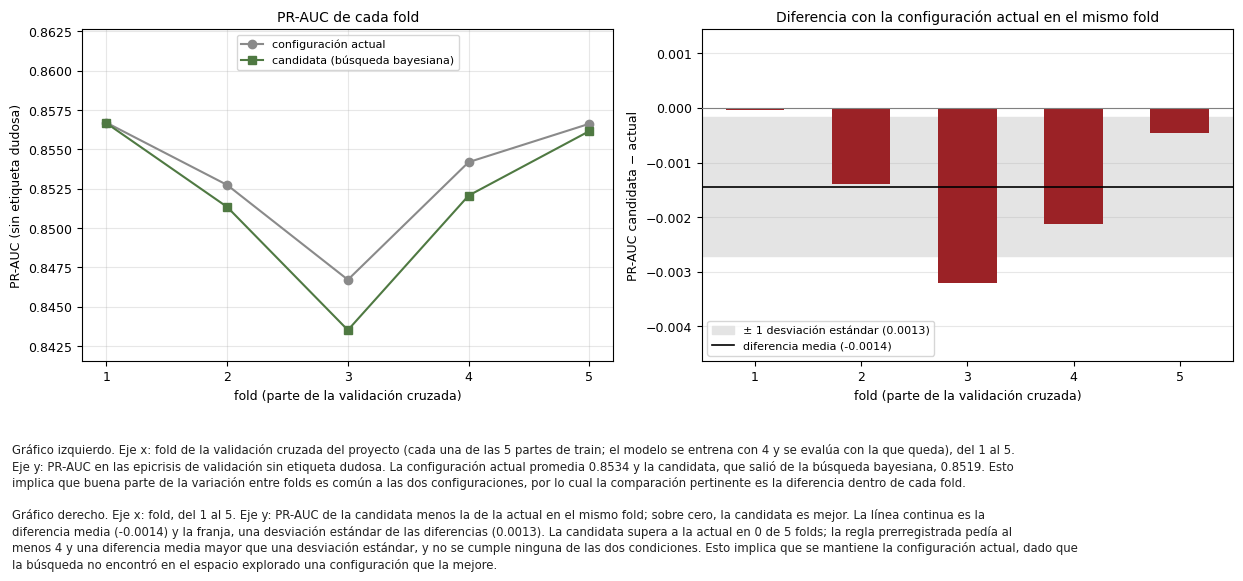

In [13]:
fig = figuras_hp.fig_folds(R)
plt.show()

Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 4 y en la Figura 3, la candidata no superó a la configuración actual en ninguno de los 5 *folds*, con una diferencia media de -0.0014 y una desviación estándar de
0.0013. La mayor diferencia en contra se dio en el *fold* 3 (-0.0032), mientras que en el *fold* 1 ambas casi
coinciden (-0.000034). Por consiguiente, no se cumple ninguna de las dos condiciones de la regla, dado que se exigía una mejora en al menos 4 de los
5 *folds* y una diferencia media mayor que una desviación estándar, y se mantiene la configuración actual. Asimismo, la ROC-AUC media de los
5 *folds* también fue menor con la candidata (0.8550 frente a 0.8582).

## 7. Medición única en *test*

Una vez aplicada la regla, la configuración actual y la candidata se reentrenaron con todas las filas de entrenamiento de D2 y se midieron una
sola vez en la partición de *test*. La Tabla 5 presenta el resultado, con el intervalo de confianza al 95% obtenido al remuestrear pacientes
200 veces.

In [14]:
filas = {}
for k in ("actual", "candidata"):
    for ev, nombre in (("comun", "sin etiqueta dudosa"), ("completa", "todas, etiqueta original")):
        t = R["test"][k][ev]
        filas[f"{k} · {nombre}"] = {"PR-AUC": t["pr_auc"], "IC 95% (pacientes)": f"{t['pr_auc_ic95_pacientes'][0]:.4f} a {t['pr_auc_ic95_pacientes'][1]:.4f}",
                                    "ROC-AUC": t["roc_auc"], "sensibilidad": t["recall"], "especificidad": t["especificidad"]}
t5 = pd.DataFrame(filas).T
t5.index.name = "Tabla 5. Test (medición única)"
t5.style.format(lambda x: f"{x:.4f}" if isinstance(x, float) else x)

,PR-AUC,IC 95% (pacientes),ROC-AUC,sensibilidad,especificidad
Tabla 5. Test (medición única),,,,,
actual · sin etiqueta dudosa,0.8671,0.8589 a 0.8749,0.8706,0.7689,0.8038
"actual · todas, etiqueta original",0.8580,0.8493 a 0.8664,0.8398,0.7189,0.7950
candidata · sin etiqueta dudosa,0.8645,0.8567 a 0.8719,0.8666,0.7629,0.8035
"candidata · todas, etiqueta original",0.8555,0.8464 a 0.8637,0.8359,0.7131,0.7950


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 5, en las epicrisis sin etiqueta dudosa la PR-AUC fue de 0.8671 con la configuración actual
y de 0.8645 con la candidata, y con todas las epicrisis fue de 0.8580 y
0.8555, respectivamente. De esta manera, el *test* repite el orden de la validación cruzada, aunque los intervalos de
confianza se solapan (0.8589 a 0.8749 frente a 0.8567 a 0.8719), por lo cual la decisión se apoya en la
comparación por *fold* y no en esta medición.

## 8. Traducción a eventos adversos por cada 10 000 hospitalizaciones

Al igual que en la semana 6, se aplicaron la sensibilidad y la especificidad medidas en *test* con el umbral de 0.5 a 10 000 hospitalizaciones
con epicrisis, con la prevalencia real de 27.6%, es decir, 2 759 hospitalizaciones con evento según los códigos. La
Tabla 6 presenta el resultado para la configuración actual y para la candidata, en las epicrisis sin etiqueta dudosa y con todas las epicrisis.

In [15]:
t6 = pd.DataFrame({f"{k} · {nombre}": R["test"][k][f"por_10000_{ev}"] for k in ("actual", "candidata")
                   for ev, nombre in (("comun", "sin etiqueta dudosa"), ("completa", "todas, etiqueta original"))}).T
t6.columns = ["con evento", "detectados (VP)", "se escapan (FN)", "falsas alarmas (FP)", "VPP: de cada 100 alertas, con evento"]
t6.index.name = f"Tabla 6. Por cada 10 000 hospitalizaciones (prevalencia real {100 * R['prevalencia_real_con_epicrisis']:.1f}%)"
t6

,con evento,detectados (VP),se escapan (FN),falsas alarmas (FP),"VPP: de cada 100 alertas, con evento"
Tabla 6. Por cada 10 000 hospitalizaciones (prevalencia real 27.6%),,,,,
actual · sin etiqueta dudosa,2759,2121,638,1421,60
"actual · todas, etiqueta original",2759,1983,776,1484,57
candidata · sin etiqueta dudosa,2759,2105,654,1423,60
"candidata · todas, etiqueta original",2759,1967,792,1484,57


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 6, en las epicrisis sin etiqueta dudosa la candidata detectaría 16 eventos
menos que la configuración actual (2 105 frente a 2 121) y daría
2 falsas alarmas más (1 423 frente a
1 421). En ambas configuraciones, 60 de cada 100 alertas tendrían evento.
Con todas las epicrisis y la etiqueta original, la candidata detectaría 16 eventos menos
(1 967 frente a 1 983) y
el mismo número de falsas alarmas.

Es preciso tomar en consideración que este cálculo supone que las tasas medidas en *test* valen para toda la base, y que los eventos son los
que marcan los códigos CIE y no el resultado de una revisión clínica de cada nota. Asimismo, la diferencia entre ambas configuraciones queda
dentro de los intervalos de confianza de la Tabla 5, por lo cual estas cifras se toman solo como orden de magnitud y no como una pérdida
demostrada.

## 9. Tiempo de cómputo

La Tabla 7 presenta el tiempo de cada etapa, en minutos, tal como lo midió el propio script.

In [16]:
NOMBRE = {"conteos_calculo_original": "conteo de palabras y bigramas (9 particiones)", "busqueda_aleatoria": "búsqueda aleatoria (reloj)",
          "busqueda_bayesiana": "búsqueda bayesiana (reloj)", "referencia_actual_busqueda": "configuración actual en 3 folds",
          "busqueda_calculo_original": "búsqueda completa (suma de ensayos y referencia)", "confirmacion": "confirmación (5 folds)",
          "test": "medición en test", "esta_corrida": "corrida principal (sin el conteo)", "computo_total": "cómputo total"}
t7 = pd.Series(R["tiempos_segundos"]).div(60).round(1).rename(NOMBRE).rename("minutos").to_frame()
t7.index.name = "Tabla 7. Etapa"
display(t7)
u = ens[ens.reutilizado_de == ""]
print("Ensayo más largo:", round(u.segundos.max() / 60, 1), "min · más corto:", round(u.segundos.min() / 60, 1), "min",
      "· cómputo total:", round(R["tiempos_segundos"]["computo_total"] / 3600, 1), "horas")

,minutos
Tabla 7. Etapa,
conteo de palabras y bigramas (9 particiones),20.3
búsqueda aleatoria (reloj),32.9
búsqueda bayesiana (reloj),37.8
configuración actual en 3 folds,2.6
búsqueda completa (suma de ensayos y referencia),73.2
confirmación (5 folds),13.3
medición en test,3.5
corrida principal (sin el conteo),90.3
cómputo total,110.3


Ensayo más largo: 8.5 min · más corto: 0.3 min · cómputo total: 1.8 horas


Fuente: elaboración propia a partir de `reportes/hp_resultados.json`.


Como se aprecia en la Tabla 7, el cómputo total fue de 110.3 minutos (1.8 horas). De ese
total, 20.3 minutos correspondieron a contar las palabras y los bigramas de las 9 particiones
(3 de búsqueda, 5 de confirmación y la de *test*), y 73.2
a la búsqueda, incluida la configuración actual en los 3 *folds* de búsqueda. Los restantes 13.3
y 3.5 minutos correspondieron a la confirmación y a la medición en *test*, respectivamente.

La caché de conteos se construyó en una corrida previa con la opción `--solo-conteos`, por lo cual la corrida principal duró
90.3 minutos. Asimismo, los ensayos con C alto fueron los más lentos (el más largo tardó 8.5
minutos y el más corto 0.3). De esta manera, la búsqueda bayesiana ocupó 37.8 minutos de
reloj frente a 32.9 de la aleatoria, aun con 5 ensayos reutilizados.

## 10. Decisión y siguiente paso

Una vez analizados los resultados, se concluye que ninguna de las 25 configuraciones evaluadas superó a la configuración actual en los
3 *folds* de búsqueda. Asimismo, la mejor de ellas, confirmada con los 5 *folds* del proyecto, quedó por
debajo en 5 de los 5 *folds*. Por consiguiente, y en aplicación de la regla fijada antes de
correr, se mantiene la configuración actual, es decir, D2 con A+B+C, C de 1, 20 000 palabras con min_df de 3, 20 000 bigramas con min_df de 3, class_weight balanced y sublinear_tf activado. De acuerdo con la Tabla 3, esa configuración ya se encuentra en la zona de mejor
desempeño del espacio explorado.

La comparación de los métodos muestra que, en esta corrida y con una sola semilla, la búsqueda bayesiana concentró mejor sus ensayos que la
aleatoria. Sin embargo, con 15 ensayos su mejor resultado solo superó al de la aleatoria en 0.0009 de
PR-AUC, diferencia menor que la desviación entre *folds* de la propia candidata (0.0024). Por ello, con una sola repetición no
se puede afirmar que un método sea mejor que el otro. Dado que se mantiene la configuración actual, HE2 y HE3 se refieren a la misma
configuración con la cual se generó el lote de la revisión ciega.

Se recomienda, como siguiente experimento del Sprint 3, evaluar el modelo por servicio, grupo de edad y decil de largo de la nota frente al
modelo de contexto, y recalibrar las probabilidades a la prevalencia real. Para reproducir el experimento se ejecuta
`python src/experimentos_hp.py`, el cual guarda en `data/interim/cache_hp/`, fuera de git, los conteos y los resultados de cada evaluación.
Una nueva corrida reutiliza esos archivos, y para repetir todo desde cero se borra esa carpeta; la corrida completa requirió
1.8 horas de cómputo en CPU.

## Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. En
*Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (Applied Data Science track).
https://arxiv.org/abs/1907.10902

Bergstra, J., Bardenet, R., Bengio, Y. y Kégl, B. (2011). Algorithms for hyper-parameter optimization. En *Advances in Neural Information
Processing Systems 24* (NIPS 2011). https://papers.nips.cc/paper_files/paper/2011/hash/86e8f7ab32cfd12577bc2619bc635690-Abstract.html

Bergstra, J. y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281-305.
https://www.jmlr.org/papers/v13/bergstra12a.html

Falkner, S., Klein, A. y Hutter, F. (2018). BOHB: Robust and efficient hyperparameter optimization at scale. En *International Conference on
Machine Learning (ICML 2018)*, PMLR 80. http://proceedings.mlr.press/v80/falkner18a.html (arXiv:1807.01774)

Optuna (s. f.). *optuna.samplers.TPESampler*. Documentación de Optuna, versión 5.0.0 (docstring de la librería instalada). Versión en línea
consultada el 28 de octubre de 2026 en https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html